# ❤️ Heart Failure Clinical Mortality Risk Prediction

**Dataset Source:** [UCI Machine Learning Repository: Heart Failure Clinical Records](https://archive.ics.uci.edu/dataset/519/heart+failure+clinical+records)

---

### Project Overview
In medical prognosis datasets, positive events are naturally in the minority (~32% mortality rate in this cohort).
To address class imbalance without risking synthetic data leakage, this pipeline applies **SMOTE (Synthetic Minority Over-sampling Technique)** directly to the training partition, followed by systematic **5-Fold Stratified GridSearchCV** using pure, standard hyperparameter spaces.

**Algorithms Tuned:**
1. **Random Forest** (`n_estimators`, `max_depth`, `min_samples_leaf`)
2. **XGBoost** (`n_estimators`, `max_depth`, `learning_rate`, `subsample`)
3. **LightGBM** (`n_estimators`, `max_depth`, `learning_rate`, `num_leaves`)
4. **Logistic Regression** (`C`)


In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    classification_report
)


## 2. Dataset Loading and Clinical Feature Engineering

In [2]:
DATA_PATH = "heart_failure_clinical_records_dataset.csv"
df = pd.read_csv(DATA_PATH)

# Add Cardiorenal Interaction Terms
df['cardiorenal_index'] = df['serum_creatinine'] / (df['ejection_fraction'] / 100.0)
df['age_to_ef'] = df['age'] / (df['ejection_fraction'] + 1e-4)
df['sodium_creatinine_ratio'] = df['serum_sodium'] / (df['serum_creatinine'] + 1e-4)

features = [
    'time', 'serum_creatinine', 'ejection_fraction', 'age', 'serum_sodium',
    'creatinine_phosphokinase', 'platelets', 'high_blood_pressure',
    'cardiorenal_index', 'age_to_ef', 'sodium_creatinine_ratio'
]
target = 'DEATH_EVENT'

print(f"Dataset Shape: {df.shape[0]} patients, {len(features)} features")
print("\nTarget Class Distribution:")
print(df[target].value_counts(normalize=True))
df.head()


Dataset Shape: 299 patients, 11 features

Target Class Distribution:
DEATH_EVENT
0    0.67893
1    0.32107
Name: proportion, dtype: float64


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT,cardiorenal_index,age_to_ef,sodium_creatinine_ratio
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1,9.500000,3.749981,68.417452
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1,2.894737,1.447365,123.625125
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1,6.500000,3.249984,99.223137
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1,9.500000,2.499988,72.101468
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1,13.500000,3.249984,42.961372


## 3. Stratified Train / Test Partitioning and SMOTE Resampling


In [3]:
X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Apply SMOTE to training set only
smote = SMOTE(k_neighbors=3, random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"Original train size: {len(X_train)} -> After SMOTE: {len(X_train_res)}")
print(f"Balanced class counts in resampled train:\n{y_train_res.value_counts()}")


Original train size: 224 -> After SMOTE: 304
Balanced class counts in resampled train:
DEATH_EVENT
1    152
0    152
Name: count, dtype: int64


## 4. Hyperparameter Optimization via 5-Fold Stratified GridSearchCV



In [4]:
models_and_grids = {
    'Random Forest': {
        'estimator': RandomForestClassifier(random_state=42),
        'params': {
            'n_estimators': [50, 100, 150],
            'max_depth': [3, 4, 6],
            'min_samples_leaf': [1, 2, 4]
        }
    },
    'XGBoost': {
        'estimator': XGBClassifier(random_state=42, eval_metric='logloss'),
        'params': {
            'n_estimators': [50, 100],
            'max_depth': [2, 3],
            'learning_rate': [0.03, 0.05, 0.1],
            'subsample': [0.8, 1.0]
        }
    },
    'LightGBM': {
        'estimator': LGBMClassifier(random_state=42, verbose=-1),
        'params': {
            'n_estimators': [50, 100],
            'max_depth': [2, 3],
            'learning_rate': [0.03, 0.05],
            'num_leaves': [7, 15]
        }
    },
    'Logistic Regression': {
        'estimator': LogisticRegression(random_state=42, max_iter=1000),
        'params': {
            'C': [0.05, 0.2, 1.0, 5.0]
        }
    }
}

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)

grid_results = {}

for name, config in models_and_grids.items():
    grid = GridSearchCV(
        estimator=config['estimator'],
        param_grid=config['params'],
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1,
        refit=True
    )

    if name == 'Logistic Regression':
        grid.fit(X_train_scaled, y_train_res)
        best_m = grid.best_estimator_
        y_prob = best_m.predict_proba(X_test_scaled)[:, 1]
        model_obj = Pipeline([('scaler', scaler), ('clf', best_m)])
    else:
        grid.fit(X_train_res, y_train_res)
        best_m = grid.best_estimator_
        y_prob = best_m.predict_proba(X_test)[:, 1]
        model_obj = best_m

    y_pred = (y_prob >= 0.50).astype(int)

    grid_results[name] = {
        '5-Fold CV ROC-AUC': grid.best_score_,
        'Test AUROC': roc_auc_score(y_test, y_prob),
        'Test AUPRC': average_precision_score(y_test, y_prob),
        'Accuracy': accuracy_score(y_test, y_pred),
        'Sensitivity (Recall)': recall_score(y_test, y_pred, zero_division=0),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'best_params': grid.best_params_,
        'y_prob': y_prob,
        'model': model_obj
    }

# Summary Table
summary_df = pd.DataFrame([{
    'Model': k,
    '5-Fold CV AUC': round(v['5-Fold CV ROC-AUC'], 4),
    'Test AUROC': round(v['Test AUROC'], 4),
    'Accuracy': round(v['Accuracy'], 4),
    'Sensitivity': round(v['Sensitivity (Recall)'], 4),
    'Precision': round(v['Precision'], 4),
    'F1 Score': round(v['F1 Score'], 4)
} for k, v in grid_results.items()])
summary_df


,Model,5-Fold CV AUC,Test AUROC,Accuracy,Sensitivity,Precision,F1 Score
0,Random Forest,0.9452,0.8693,0.8267,0.7500,0.7200,0.7347
1,XGBoost,0.9589,0.8627,0.8000,0.6667,0.6957,0.6809
2,LightGBM,0.9590,0.8619,0.8400,0.7083,0.7727,0.7391
3,Logistic Regression,0.9234,0.8709,0.7867,0.6667,0.6667,0.6667


## 5. ROC Curves and Feature Importance Comparison


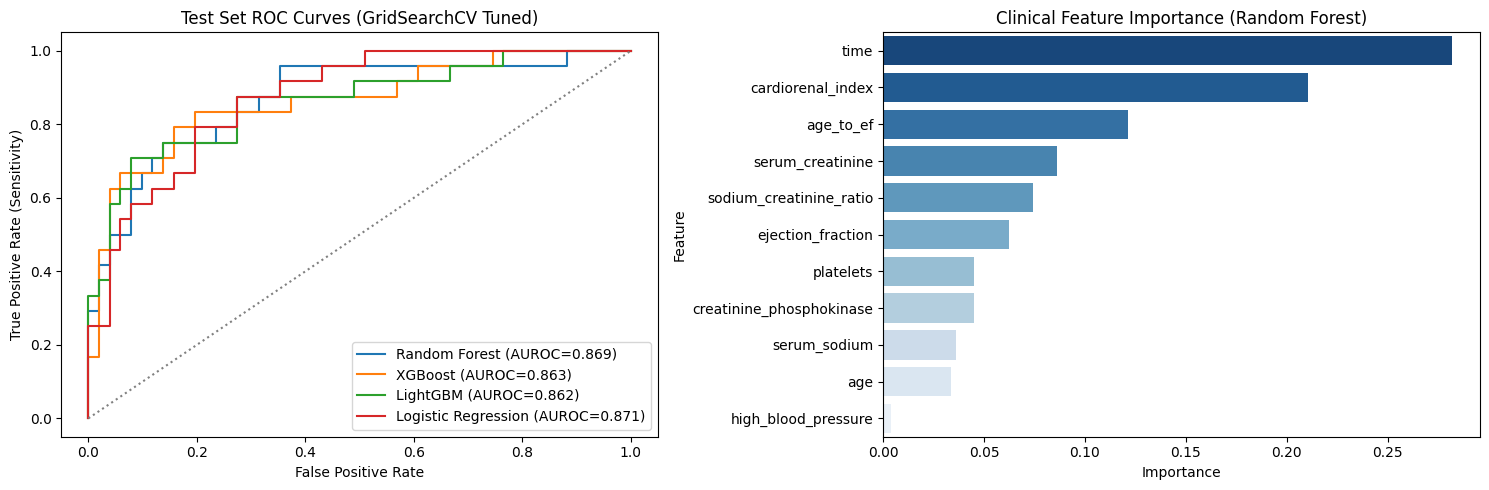

In [5]:
fig, (ax_roc, ax_fi) = plt.subplots(1, 2, figsize=(15, 5))

# ROC Curves
for name, res in grid_results.items():
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    ax_roc.plot(fpr, tpr, label=f"{name} (AUROC={res['Test AUROC']:.3f})")

ax_roc.plot([0, 1], [0, 1], 'gray', linestyle=':')
ax_roc.set_title('Test Set ROC Curves (GridSearchCV Tuned)')
ax_roc.set_xlabel('False Positive Rate')
ax_roc.set_ylabel('True Positive Rate (Sensitivity)')
ax_roc.legend()

# Feature Importance
rf_m = grid_results['Random Forest']['model']
fi_df = pd.DataFrame({
    'Feature': features,
    'Importance': rf_m.feature_importances_
}).sort_values('Importance', ascending=False)

sns.barplot(
    ax=ax_fi, 
    x='Importance', 
    y='Feature', 
    hue='Feature', 
    data=fi_df, 
    palette='Blues_r', 
    legend=False
)
ax_fi.set_title('Clinical Feature Importance (Random Forest)')
plt.tight_layout()
plt.show()


## 6. Confusion Matrix and Classification Report: Random Forest


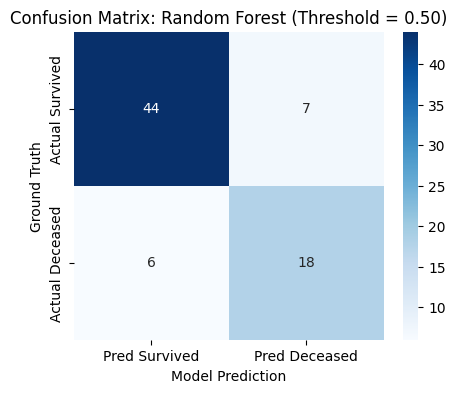


Classification Report:
              precision    recall  f1-score   support

    Survived       0.88      0.86      0.87        51
    Deceased       0.72      0.75      0.73        24

    accuracy                           0.83        75
   macro avg       0.80      0.81      0.80        75
weighted avg       0.83      0.83      0.83        75



In [6]:
rf_res = grid_results['Random Forest']
y_pred_rf = (rf_res['y_prob'] >= 0.50).astype(int)
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred Survived', 'Pred Deceased'],
            yticklabels=['Actual Survived', 'Actual Deceased'])
plt.title("Confusion Matrix: Random Forest (Threshold = 0.50)")
plt.ylabel('Ground Truth')
plt.xlabel('Model Prediction')
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=['Survived', 'Deceased']))


## 7. Export Production Artifacts for Streamlit Deployment


In [7]:
bundle = {
    'features': features,
    'feature_summary': df[features].describe().T[['mean', 'std', 'min', 'max', '50%']].to_dict(orient='index'),
    'models': {k: v['model'] for k, v in grid_results.items()},
    'eval_results': {k: {
        '5-Fold CV ROC-AUC': round(v['5-Fold CV ROC-AUC'], 4),
        'Test AUROC': round(v['Test AUROC'], 4),
        'Test AUPRC': round(v['Test AUPRC'], 4),
        'Accuracy': round(v['Accuracy'], 4),
        'Sensitivity/Recall': round(v['Sensitivity (Recall)'], 4),
        'Precision': round(v['Precision'], 4),
        'F1 Score': round(v['F1 Score'], 4),
        'Optimal Threshold': 0.50
    } for k, v in grid_results.items()},
    'best_params': {k: v['best_params'] for k, v in grid_results.items()},
    'feature_importance': fi_df.to_dict(orient='records'),
    'dataset_sample': df[features + ['DEATH_EVENT']].head(40).to_dict(orient='records')
}

joblib.dump(bundle, 'heart_failure_bundle.joblib')
print("Model bundle exported successfully to heart_failure_bundle.joblib!")


Model bundle exported successfully to heart_failure_bundle.joblib!
